# ДЗ №2. Семантическая сегментация кожных поражений

**Источник данных:** [Dataset Ninja — Skin Cancer: HAM10000](https://datasetninja.com/skin-cancer-ham10000) (версия с масками Supervisely).

**Задача:** самостоятельно реализовать **одну** компактную архитектуру сегментации (encoder–decoder со skip-связью), обучить её как минимум **дважды** при изменении одного параметра и сравнить результаты.

В блокноте уже подготовлены чтение изображений и разметки, формирование фиксированных выборок, `Dataset`, `DataLoader` и визуальная проверка данных. **Реализацию архитектуры, обучение, вычисление метрики и экспериментальное сравнение выполняете самостоятельно.**

Полное условие и критерии: [страница домашнего задания](https://ai-mai-307.github.io/ml-dl-course-site/courses/deep-learning/2026-fall/assignments/hw-02/).

## 1. Скачивание и распаковка датасета

1. Откройте [Skin Cancer: HAM10000 — Dataset Ninja](https://datasetninja.com/skin-cancer-ham10000), выберите **Download** для **полного архива Supervisely** (около 2,6 ГБ). Обычный HAM10000 без аннотаций и **Download Sample** не подходят для итоговых экспериментов.
2. Распакуйте архив в каталог `data/` рядом с `solution.ipynb`. Пример из PowerShell в папке с ноутбуком:

   ```powershell
   New-Item -ItemType Directory -Force data
   tar -xf "ИМЯ_СКАЧАННОГО_АРХИВА.tar" -C data
   ```

   Не переименовывайте файлы внутри архива. Если после распаковки возникли дополнительные вложенные папки, изменять их структуру не нужно: следующий код рекурсивно найдёт `img/` и `ann/`.
3. Установите зависимости в используемое Python-окружение (если их ещё нет):

   ```powershell
   python -m pip install torch numpy pandas pillow matplotlib scikit-learn
   ```

Файл `dataset_meta_comp.csv` **не нужен**: таблица `ds_df` и разбиение создаются автоматически. При запуске Jupyter текущая рабочая папка должна совпадать с папкой, где лежат `solution.ipynb` и `data/`.

## 2. Импорт библиотек и фиксированные параметры

In [1]:
import base64
import io
import json
import random
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset


def set_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
set_random_seeds(SEED)

DATA_DIR = Path("data")
IMAGE_SIZE = (96, 128)       # (H, W); фиксируется для обоих экспериментов
MAX_TRAIN_PER_CLASS = 120    # фиксируется для обоих экспериментов
MAX_VAL_PER_CLASS = 30      # фиксируется для обоих экспериментов
BATCH_SIZE = 4              # одинаковый на CPU и GPU
NUM_WORKERS = 0             # без дополнительных процессов (удобно для Windows)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MIN_EPOCHS = 8              # минимальное число эпох для КАЖДОГО запуска
M_MIN = 0.05               # минимальная val mIoU для базовой модели
MIN_TRAIN_LOSS_DROP = 0.20 # средний train loss: последние 3 эпохи против первых 3

print(f"PyTorch {torch.__version__} | Устройство: {DEVICE}")
print(f"Папка данных: {DATA_DIR.resolve()}")

PyTorch 2.7.1+cu128 | Устройство: cuda
Папка данных: D:\Технологии ИИ\hw-02\data


## 3. Таблица изображений и метаданных

В архиве Dataset Ninja отсутствуют собственные `train/val`-метки и файл метаданных. Здесь мы находим JSON-аннотации в формате Supervisely, восстанавливаем имена файлов и список классов.

Два изображения без bitmap-разметки исключаются. Валидация построена как **воспроизводимое стратифицированное разбиение по классу изображения**.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка {DATA_DIR.resolve()}. Сначала распакуйте архив Dataset Ninja в data/."
    )

annotation_files = sorted(DATA_DIR.rglob("ann/*.json"))
if not annotation_files:
    raise FileNotFoundError(
        f"В {DATA_DIR.resolve()} не найдены ann/*.json. "
        "Проверьте, что скачан архив Supervisely (с аннотациями), а не исходный HAM10000."
    )

rows = []
ignored_without_bitmap = 0
missing_images = []
for ann_path in annotation_files:
    with ann_path.open("r", encoding="utf-8") as f:
        ann = json.load(f)

    objects = [obj for obj in ann.get("objects", []) if obj.get("bitmap")]
    if not objects:
        ignored_without_bitmap += 1
        continue

    # Имена файлов Supervisely: ISIC_....jpg и ISIC_....jpg.json
    img_name = ann_path.name.removesuffix(".json")
    img_path = ann_path.parent.parent / "img" / img_name
    if not img_path.is_file():
        missing_images.append(str(img_path))
        continue

    class_titles = [obj["classTitle"] for obj in objects]
    class_name = Counter(class_titles).most_common(1)[0][0]
    rows.append({
        "img_name": img_name,
        "ann_name": ann_path.name,
        "class_name": class_name,
        "img_path": img_path,
        "ann_path": ann_path,
    })

if missing_images:
    raise FileNotFoundError(
        f"Для {len(missing_images)} аннотаций не найдены изображения. "
        f"Первое: {missing_images[0]}"
    )
if not rows:
    raise ValueError("Не найдено ни одного изображения с bitmap-аннотацией.")

ds_df = pd.DataFrame(rows).sort_values("img_name").reset_index(drop=True)

# Порядок по алфавиту соответствует исходной таблице преподавателя:
# 1=actinic keratoses, 2=basal cell carcinoma, 3=benign keratosis-like lesions,
# 4=dermatofibroma, 5=melanocytic nevi, 6=melanoma, 7=vascular lesions.
CLASS_NAMES = sorted(ds_df["class_name"].unique(), key=str.casefold)
CLASS_TO_INDEX = {name: idx + 1 for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES) + 1  # ещё один класс — фон = 0

if NUM_CLASSES != 8:
    raise ValueError(
        f"Ожидались 7 диагностических классов и фон, получено: {CLASS_NAMES}. "
        "Если скачан только Sample, проверьте полный архив."
    )

ds_df["class_index"] = ds_df["class_name"].map(CLASS_TO_INDEX).astype(int)
print(f"Изображений с масками: {len(ds_df)}; без bitmap: {ignored_without_bitmap}")
print("Классы: 0 — фон")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index} — {name}")
display(ds_df[["img_name", "class_name", "class_index"]].head())

Изображений с масками: 10013; без bitmap: 2
Классы: 0 — фон
  1 — actinic keratoses
  2 — basal cell carcinoma
  3 — benign keratosis-like lesions
  4 — dermatofibroma
  5 — melanocytic nevi
  6 — melanoma
  7 — vascular lesions


,img_name,class_name,class_index
0,ISIC_0024306.jpg,melanocytic nevi,5
1,ISIC_0024307.jpg,melanocytic nevi,5
2,ISIC_0024308.jpg,melanocytic nevi,5
3,ISIC_0024309.jpg,melanocytic nevi,5
4,ISIC_0024310.jpg,melanoma,6


In [3]:
train_df, val_df = train_test_split(
    ds_df,
    test_size=0.20,
    stratify=ds_df["class_index"],
    random_state=SEED,
)
train_df = train_df.copy().assign(split="train")
val_df = val_df.copy().assign(split="val")
ds_df = pd.concat([train_df, val_df], ignore_index=True)

assert set(train_df["img_path"]).isdisjoint(set(val_df["img_path"]))


def limit_per_class(frame, maximum):
    if maximum is None:
        return frame.sort_values("img_name").reset_index(drop=True)
    indices = []
    for _, group in frame.groupby("class_index"):
        n = min(len(group), maximum)
        indices.extend(group.sample(n=n, random_state=SEED).index.tolist())
    return frame.loc[indices].sort_values("img_name").reset_index(drop=True)


train_used = limit_per_class(train_df, MAX_TRAIN_PER_CLASS)
val_used = limit_per_class(val_df, MAX_VAL_PER_CLASS)
print(f"Train: {len(train_df)} всего, {len(train_used)} используются")
print(f"Val:   {len(val_df)} всего, {len(val_used)} используются")
print("Валидационные классы:", val_used["class_index"].value_counts().sort_index().to_dict())
assert val_used["class_index"].nunique() == NUM_CLASSES - 1, "В val представлены не все семь классов"
assert train_used["class_index"].nunique() == NUM_CLASSES - 1, "В train представлены не все семь классов"
assert set(train_used["img_path"]).isdisjoint(set(val_used["img_path"]))

Train: 8010 всего, 806 используются
Val:   2003 всего, 201 используются
Валидационные классы: {1: 30, 2: 30, 3: 30, 4: 23, 5: 30, 6: 30, 7: 28}


## 4. Преобразование Supervisely-масок и `Dataset`

Разметка хранится как `base64 → zlib → PNG` вместе со смещением `bitmap.origin`. Область объекта извлекается из **альфа-канала** PNG. Изображение масштабируется билинейно, маска — методом ближайшего соседа, чтобы индексы классов не смешивались.

`SkinCancerDataset[i]` возвращает тройку `(image, mask, class_index)`:

- `image`: `torch.float32`, форма `[3, H, W]`, нормировка в `[-1, 1]`;
- `mask`: `torch.int64`, форма `[H, W]`, метки `0..7` (`0` — фон);
- `class_index`: диагностический класс изображения (1–7).

Изображения и маски читаются **по требованию**: весь архив вряд ли поместится в оперативную память.

In [4]:
def decode_supervisely_bitmap_to_binary(mask_data_b64):
    raw = base64.b64decode(mask_data_b64)
    try:
        raw = zlib.decompress(raw)
    except zlib.error:
        # На случай, если данные уже содержат PNG без zlib-сжатия.
        pass
    with Image.open(io.BytesIO(raw)) as bitmap_image:
        rgba = np.asarray(bitmap_image.convert("RGBA"))
    return (rgba[..., 3] > 0).astype(np.uint8)


class SkinCancerDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size  # (H, W)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        h, w = self.image_size

        with Image.open(row["img_path"]) as img:
            img = img.convert("RGB")
            original_w, original_h = img.size
            img = img.resize((w, h), resample=Image.Resampling.BILINEAR)
            img_array = np.asarray(img).copy()

        image = torch.from_numpy(img_array).permute(2, 0, 1).float() / 255.0
        image = (image - 0.5) / 0.5

        # Сначала маска в исходном разрешении, потом NEAREST-resize.
        full_mask = np.zeros((original_h, original_w), dtype=np.uint8)
        with Path(row["ann_path"]).open("r", encoding="utf-8") as f:
            annotation = json.load(f)

        for obj in annotation.get("objects", []):
            if not obj.get("bitmap"):
                continue
            class_title = obj["classTitle"]
            class_index = CLASS_TO_INDEX[class_title]
            bitmap = obj["bitmap"]
            small_mask = decode_supervisely_bitmap_to_binary(bitmap["data"])
            x0, y0 = map(int, bitmap["origin"])
            mh, mw = small_mask.shape

            x_start, y_start = max(0, x0), max(0, y0)
            x_end, y_end = min(original_w, x0 + mw), min(original_h, y0 + mh)
            if x_start >= x_end or y_start >= y_end:
                continue

            crop = small_mask[
                y_start - y0 : y_end - y0,
                x_start - x0 : x_end - x0,
            ]
            patch = full_mask[y_start:y_end, x_start:x_end]
            patch[crop > 0] = class_index

        mask_resized = Image.fromarray(full_mask).resize(
            (w, h), resample=Image.Resampling.NEAREST
        )
        mask = torch.from_numpy(np.asarray(mask_resized).copy()).long()
        return image, mask, int(row["class_index"])

## 5. `DataLoader` и проверка данных

В начале **каждого** обучения создавайте загрузчики заново через `make_dataloaders(SEED)` и вызывайте `set_random_seeds(SEED)` **перед созданием модели**. Это позволит корректно сравнить две конфигурации на одинаковом составе данных, с одинаковой инициализацией и порядком батчей.

Следующая ячейка проверяет тензоры одного батча и присутствие **всех семи классов в пиксельных масках `val`**. Проверка может занять некоторое время, так как разметка читается с диска.

In [5]:
train_dataset = SkinCancerDataset(train_used)
val_dataset = SkinCancerDataset(val_used)


def make_dataloaders(seed=SEED):
    train = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    val = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    return train, val


train_loader, val_loader = make_dataloaders()
images, masks, classes = next(iter(train_loader))
print("Изображения:", images.shape, images.dtype)
print("Маски:      ", masks.shape, masks.dtype)
print("Классы:    ", classes.tolist())
print("Метки масок:", torch.unique(masks).tolist())

assert images.shape[1:] == (3, *IMAGE_SIZE)
assert masks.shape[1:] == IMAGE_SIZE and masks.dtype == torch.int64
assert 0 <= masks.min().item() and masks.max().item() < NUM_CLASSES

val_pixel_classes = set()
for _, batch_masks, _ in val_loader:
    val_pixel_classes.update(torch.unique(batch_masks).tolist())

missing_classes = set(range(1, NUM_CLASSES)) - val_pixel_classes
print("Классы, присутствующие в val-масках:", sorted(val_pixel_classes))
assert not missing_classes, f"В пиксельных val-масках отсутствуют классы: {sorted(missing_classes)}"

Изображения:

 torch.Size([4, 3, 96, 128]) torch.float32
Маски:       torch.Size([4, 96, 128]) torch.int64
Классы:     [1, 2, 4, 6]
Метки масок: [0, 1, 2, 4, 6]


Классы, присутствующие в val-масках: [0, 1, 2, 3, 4, 5, 6, 7]


### Проверка соответствия изображения и маски

Ниже выводятся три изображения **разных диагностических классов**, соответствующие им маски и наложение. Визуально убедитесь, что разметка совпадает с областями поражений, и прокомментируйте замеченные особенности данных.

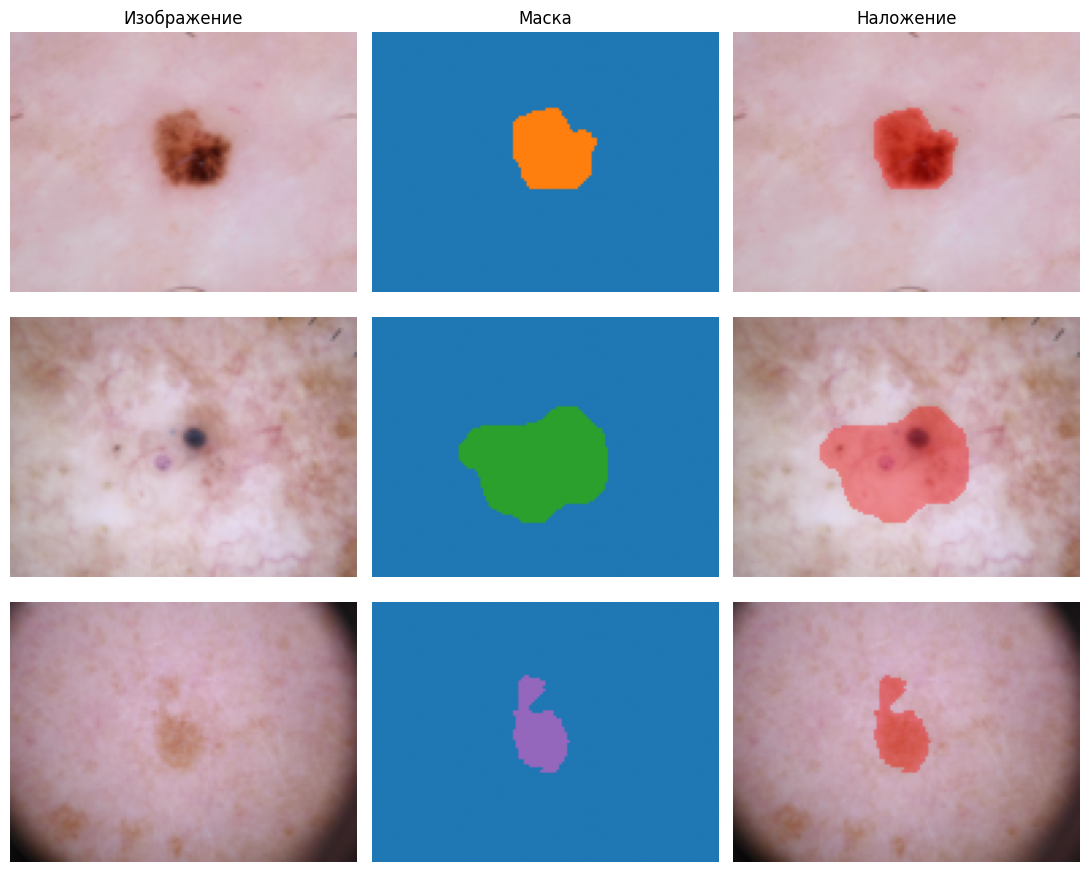

In [6]:
# Берём по одному примеру из трёх разных классов.
example_indices = [
    int(train_used.index[train_used["class_index"] == cls][0])
    for cls in sorted(train_used["class_index"].unique())[:3]
]

fig, axes = plt.subplots(len(example_indices), 3, figsize=(11, 9))
for row_number, example_index in enumerate(example_indices):
    image, mask, class_ind = train_dataset[example_index]
    img = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    overlay = img.copy()
    overlay[mask_np > 0] = (
        0.65 * overlay[mask_np > 0] + 0.35 * np.array([1.0, 0.0, 0.0])
    )
    axes[row_number, 0].imshow(img)
    axes[row_number, 1].imshow(mask_np, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row_number, 2].imshow(overlay)
    axes[row_number, 0].set_ylabel(f"Класс {class_ind}", rotation=90)
    for ax in axes[row_number]:
        ax.axis("off")

for ax, heading in zip(axes[0], ["Изображение", "Маска", "Наложение"]):
    ax.set_title(heading)
plt.tight_layout()
plt.show()

## 6. Самостоятельная реализация модели

**Реализуйте одну собственную компактную архитектуру `encoder–decoder` с хотя бы одной `skip`-связью**. Пользуйтесь базовыми слоями PyTorch (`torch.nn.Conv2d`, `MaxPool2d`, `ConvTranspose2d`, `BatchNorm2d` и т. п.). **Не используйте готовые модели** (`torchvision.models`, `timm`, `segmentation_models_pytorch` и аналоги) **или предобученные веса**.

Для входа `[B, 3, H, W]` выходом должны быть **логиты** `[B, 8, H, W]`. При `nn.CrossEntropyLoss` не вызывайте `softmax` до функции потерь. Кратко опишите выбранную архитектуру, в том числе skip-связь.

In [7]:
def check_model_output_shape(model, example_batch, device=DEVICE):
    inputs = example_batch.to(device)
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(inputs)
    expected = (inputs.shape[0], NUM_CLASSES, *inputs.shape[-2:])
    assert logits.shape == expected, (tuple(logits.shape), expected)
    assert logits.is_floating_point()
    print("Размерность выхода:", tuple(logits.shape))


class ConvBlock(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            torch.nn.BatchNorm2d(out_channels),
            torch.nn.ReLU(inplace=True),
            torch.nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            torch.nn.BatchNorm2d(out_channels),
            torch.nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class SmallUNet(torch.nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.pool = torch.nn.MaxPool2d(2)
        self.middle = ConvBlock(32, 64)
        self.up2 = torch.nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(64, 32)
        self.up1 = torch.nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(32, 16)
        self.output = torch.nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        skip1 = self.enc1(x)
        skip2 = self.enc2(self.pool(skip1))
        x = self.middle(self.pool(skip2))
        x = self.up2(x)
        x = self.dec2(torch.cat([x, skip2], dim=1))
        x = self.up1(x)
        x = self.dec1(torch.cat([x, skip1], dim=1))
        return self.output(x)


model = SmallUNet().to(DEVICE)
check_model_output_shape(model, images[:2])


Размерность выхода: (2, 8, 96, 128)


Архитектура: два блока свёрток уменьшают размер признаков через pooling, центральный блок обрабатывает их, затем decoder увеличивает размер через транспонированные свёртки. На каждом уровне decoder соединяется с соответствующим выходом encoder (skip-связь). Последняя свёртка выдаёт 8 каналов логитов: фон и 7 классов.


## 7. Метрика: Mean Intersection over Union

Реализуйте расчёт mIoU по **семи классам поражений, исключая фон (класс 0)**:

$$
\mathrm{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}, \qquad
\mathrm{mIoU} = \frac{1}{7}\sum_{c=1}^{7}\mathrm{IoU}_c.
$$

**Сначала суммируйте** `TP`, `FP`, `FN` **по всей валидационной выборке**, затем вычисляйте IoU каждого класса. Не усредняйте IoU отдельных батчей. Вычисляйте индексы предсказанных классов через `argmax` по размерности каналов логитов. В блокноте выше проверено наличие пикселей всех семи классов в `val`.

Для самопроверки: если все пиксели предсказаны как фон, то `mIoU = 0`. Это **не считается успешным обучением**.

In [8]:
def mean_iou_from_confusion(confusion):
    scores = []
    for class_id in range(1, NUM_CLASSES):
        tp = confusion[class_id, class_id]
        fp = confusion[:, class_id].sum() - tp
        fn = confusion[class_id, :].sum() - tp
        denominator = tp + fp + fn
        scores.append((tp / denominator).item() if denominator > 0 else 0.0)
    return float(np.mean(scores))


def update_confusion(confusion, logits, masks):
    predictions = logits.argmax(dim=1)
    encoded = masks.reshape(-1) * NUM_CLASSES + predictions.reshape(-1)
    counts = torch.bincount(encoded, minlength=NUM_CLASSES * NUM_CLASSES)
    confusion += counts.reshape(NUM_CLASSES, NUM_CLASSES)
    return predictions


def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_images = 0
    confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=DEVICE
    )
    predictions_by_batch = []

    with torch.no_grad():
        for images, masks, _ in loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            logits = model(images)
            loss = criterion(logits, masks)
            total_loss += loss.item() * images.shape[0]
            total_images += images.shape[0]
            predictions = update_confusion(confusion, logits, masks)
            predictions_by_batch.append(predictions.cpu())

    val_loss = total_loss / total_images
    val_miou = mean_iou_from_confusion(confusion.cpu())
    return val_loss, val_miou, predictions_by_batch


print("Функции mIoU и проверки на validation готовы.")


Функции mIoU и проверки на validation готовы.


## 8. Обучение базовой модели

Самостоятельно реализуйте цикл обучения и валидации. Необходимо:

- обучать с обновлением параметров (`zero_grad → backward → optimizer.step`);
- проверять модель в режиме `eval()` **без обновления весов**;
- сохранять за каждую эпоху `train loss`, `val loss` и **`val mIoU`**;
- провести **не менее 8 эпох**; средний `train loss` за **последние три** эпохи должен быть как минимум **на 20% ниже**, чем за **первые три**;
- получить `val mIoU ≥ 0.05` **для базовой модели** и показать маски, не сводящиеся к одному фону.

Как отправная точка подходят `torch.nn.CrossEntropyLoss()` и `torch.optim.Adam`, но гиперпараметры вы должны выбрать самостоятельно. Модель обязана обучаться даже при отсутствии GPU — уменьшать число изображений или обязательные эпохи нельзя.

**Перед созданием модели и загрузчиков:** повторно вызовите `set_random_seeds(SEED)` и `train_loader, val_loader = make_dataloaders(SEED)`.

In [9]:
def train_model(model, train_loader, val_loader, learning_rate, epochs):
    class_weights = torch.tensor(
        [0.15] + [1.0] * (NUM_CLASSES - 1), dtype=torch.float32, device=DEVICE
    )
    criterion = torch.nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {"train_loss": [], "val_loss": [], "val_miou": []}

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        image_count = 0

        for images, masks, _ in train_loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * images.shape[0]
            image_count += images.shape[0]

        train_loss = loss_sum / image_count
        val_loss, val_miou, _ = evaluate_model(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_miou"].append(val_miou)

        print(
            f"Эпоха {epoch + 1}/{epochs}: "
            f"train loss={train_loss:.4f}, "
            f"val loss={val_loss:.4f}, val mIoU={val_miou:.4f}"
        )

    return history, criterion


EPOCHS = 24
BASELINE_LR = 1e-3

set_random_seeds(SEED)
train_loader, val_loader = make_dataloaders(SEED)
model = SmallUNet().to(DEVICE)
history_baseline, criterion_baseline = train_model(
    model, train_loader, val_loader, BASELINE_LR, EPOCHS
)


Эпоха 1/24: train loss=1.8531, val loss=1.6850, val mIoU=0.0876


Эпоха 2/24: train loss=1.6664, val loss=1.5907, val mIoU=0.1305


Эпоха 3/24: train loss=1.5997, val loss=1.5295, val mIoU=0.1388


Эпоха 4/24: train loss=1.5678, val loss=1.4976, val mIoU=0.1265


Эпоха 5/24: train loss=1.5383, val loss=1.5541, val mIoU=0.1320


Эпоха 6/24: train loss=1.5136, val loss=1.4274, val mIoU=0.1594


... (14 outputs left out)

Эпоха 21/24: train loss=1.3204, val loss=1.3043, val mIoU=0.2051


Эпоха 22/24: train loss=1.3383, val loss=1.3049, val mIoU=0.2218


Эпоха 23/24: train loss=1.3185, val loss=1.3269, val mIoU=0.1977


Эпоха 24/24: train loss=1.3227, val loss=1.3520, val mIoU=0.1888


## 9. Один дополнительный эксперимент

**Заново обучите ту же архитектуру с той же начальной инициализацией**, изменив **один** фактор (например, функцию потерь, скорость обучения или аугментации). Обучайте не менее 8 эпох.

Состав `train/val`, размер изображений, `BATCH_SIZE`, `SEED` и условия сравнения должны совпадать. Для честного сравнения перед созданием второй модели и новых загрузчиков **снова** выполните `set_random_seeds(SEED)` и `make_dataloaders(SEED)`.

Улучшение `val mIoU` во втором запуске **не обязательно** — важны корректный эксперимент и содержательный вывод.

In [10]:
# Гипотеза: при меньшем learning rate обновления будут осторожнее.
# Меняем только learning rate; seed, данные, batch size, модель и эпохи те же.
EXPERIMENT_LR = 3e-4

set_random_seeds(SEED)
train_loader_exp, val_loader_exp = make_dataloaders(SEED)
model_exp = SmallUNet().to(DEVICE)
history_experiment, criterion_experiment = train_model(
    model_exp, train_loader_exp, val_loader_exp, EXPERIMENT_LR, EPOCHS
)


Эпоха 1/24: train loss=1.9684, val loss=1.7888, val mIoU=0.1187


Эпоха 2/24: train loss=1.7739, val loss=1.6819, val mIoU=0.1220


Эпоха 3/24: train loss=1.6593, val loss=1.6036, val mIoU=0.1330


Эпоха 4/24: train loss=1.5856, val loss=1.5087, val mIoU=0.1591


Эпоха 5/24: train loss=1.5406, val loss=1.5017, val mIoU=0.1473


Эпоха 6/24: train loss=1.5000, val loss=1.4167, val mIoU=0.1754


... (14 outputs left out)

Эпоха 21/24: train loss=1.2843, val loss=1.2581, val mIoU=0.2290


Эпоха 22/24: train loss=1.3048, val loss=1.2705, val mIoU=0.2347


Эпоха 23/24: train loss=1.2917, val loss=1.2993, val mIoU=0.2039


Эпоха 24/24: train loss=1.2951, val loss=1.2989, val mIoU=0.2097


## 10. Графики, визуализация и выводы

Необходимо предоставить:

1. Графики `train loss`, `val loss` и `val mIoU` по эпохам **для двух запусков**.
2. Для **трёх валидационных изображений**: фото, истинная маска, предсказанная маска базовой модели. Прокомментируйте хотя бы один пример ошибки.
3. **Таблицу результатов** с фактическим числом эпох, параметрами и итоговыми метриками двух экспериментов:

| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| Baseline | — | … | … | … | … | … |
| Эксперимент 2 | … | … | … | … | … | … |

Итоговый вывод: что именно изменили, как это повлияло на обучение/качество и какие ограничения выявлены. Сохраните результаты выполнения в ноутбуке, но **не добавляйте датасет и веса модели в репозиторий**.

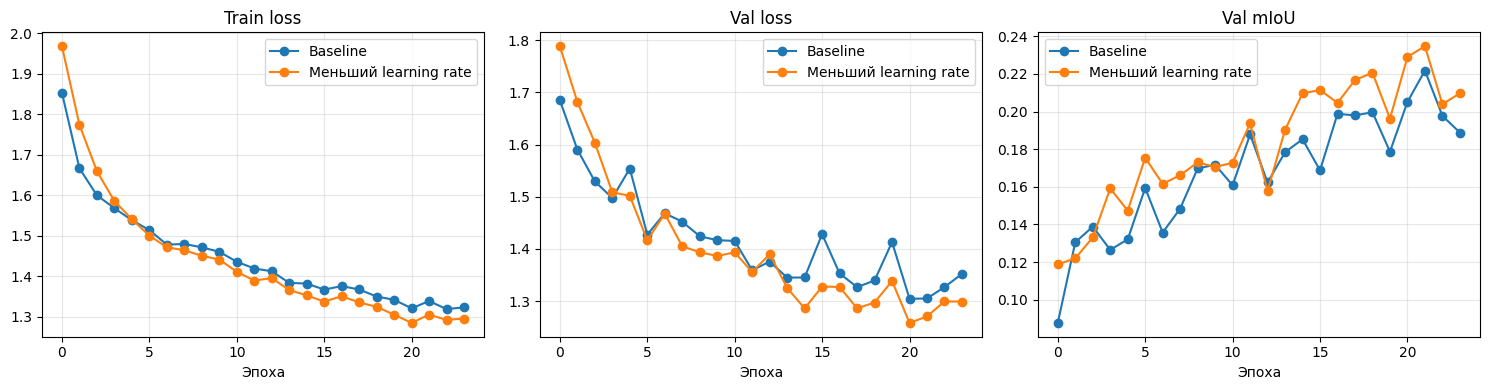

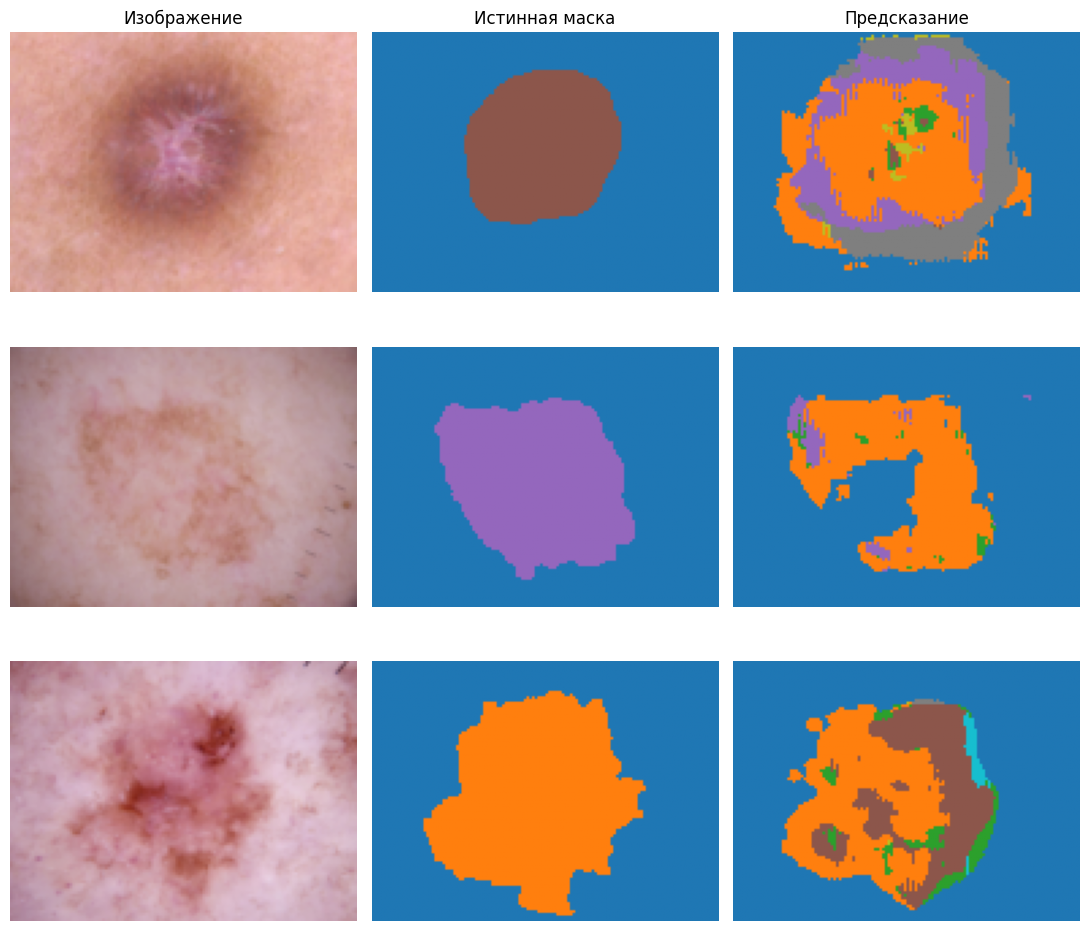

На первом примере диагностического класса 4 доля пикселей поражения, пропущенных как фон: 0.0%. Ложных пикселей поражения на фоне: 3369.


,Запуск,Изменение,Архитектура,Loss,Optimizer,LR,Эпох,Train loss,Val loss,Val mIoU,Снижение train loss
0,Baseline,нет,"SmallUNet, каналы 16-32-64",weighted CrossEntropyLoss,Adam,0.0010,24,1.3227,1.3520,0.1888,0.2226
1,Эксперимент 2,learning rate уменьшен,"SmallUNet, каналы 16-32-64",weighted CrossEntropyLoss,Adam,0.0003,24,1.2951,1.2989,0.2097,0.2796


Проверка числа эпох: 24 (нужно не менее 8)
Снижение train loss: 22.3% (нужно не менее 20%)
Базовый val mIoU: 0.1888 (нужно не менее 0.05)
В предсказаниях есть классы помимо фона: True
Вывод: во втором запуске изменён только learning rate. Baseline получил val mIoU=0.1888, эксперимент=0.2097. Сравнение показывает, как размер шага оптимизатора повлиял на обучение.


In [11]:
histories = [
    ("Baseline", history_baseline),
    ("Меньший learning rate", history_experiment),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, history in histories:
    axes[0].plot(history["train_loss"], marker="o", label=name)
    axes[1].plot(history["val_loss"], marker="o", label=name)
    axes[2].plot(history["val_miou"], marker="o", label=name)

axes[0].set_title("Train loss")
axes[1].set_title("Val loss")
axes[2].set_title("Val mIoU")
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


def predict_one(model, dataset, index):
    image, mask, class_index = dataset[index]
    model.eval()
    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(DEVICE))
    prediction = logits.argmax(dim=1)[0].cpu()
    return image, mask, prediction, class_index


# Берём три validation-изображения разных диагностических классов.
selected_indices = []
used_classes = set()
for index in range(len(val_dataset)):
    _, _, class_index = val_dataset[index]
    if class_index not in used_classes:
        selected_indices.append(index)
        used_classes.add(class_index)
    if len(selected_indices) == 3:
        break

fig, axes = plt.subplots(3, 3, figsize=(11, 10))
shown_predictions = []
for row, index in enumerate(selected_indices):
    image, true_mask, prediction, class_index = predict_one(model, val_dataset, index)
    shown_predictions.append((true_mask, prediction, class_index))
    image = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(true_mask.numpy(), cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row, 2].imshow(prediction.numpy(), cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row, 0].set_ylabel(f"Класс {class_index}")
    for ax in axes[row]:
        ax.axis("off")

for ax, title in zip(axes[0], ["Изображение", "Истинная маска", "Предсказание"]):
    ax.set_title(title)
plt.tight_layout()
plt.show()


# Численно разбираем ошибки на первом показанном примере.
true_mask, predicted_mask, example_class = shown_predictions[0]
lesion_pixels = true_mask > 0
if lesion_pixels.any():
    missed_as_background = ((predicted_mask == 0) & lesion_pixels).sum().item()
    lesion_count = lesion_pixels.sum().item()
    false_positive = ((predicted_mask > 0) & (true_mask == 0)).sum().item()
    print(
        f"На первом примере диагностического класса {example_class} "
        f"доля пикселей поражения, пропущенных как фон: "
        f"{missed_as_background / lesion_count:.1%}. "
        f"Ложных пикселей поражения на фоне: {false_positive}."
    )


def experiment_row(name, change, history, lr):
    first_three = float(np.mean(history["train_loss"][:3]))
    last_three = float(np.mean(history["train_loss"][-3:]))
    return {
        "Запуск": name,
        "Изменение": change,
        "Архитектура": "SmallUNet, каналы 16-32-64",
        "Loss": "weighted CrossEntropyLoss",
        "Optimizer": "Adam",
        "LR": lr,
        "Эпох": len(history["train_loss"]),
        "Train loss": history["train_loss"][-1],
        "Val loss": history["val_loss"][-1],
        "Val mIoU": history["val_miou"][-1],
        "Снижение train loss": 1 - last_three / first_three,
    }


summary = pd.DataFrame([
    experiment_row("Baseline", "нет", history_baseline, BASELINE_LR),
    experiment_row("Эксперимент 2", "learning rate уменьшен", history_experiment, EXPERIMENT_LR),
])
display(summary.round(4))

baseline_drop = (
    1 - np.mean(history_baseline["train_loss"][-3:])
    / np.mean(history_baseline["train_loss"][:3])
)
predicted_classes = set()
for batch_predictions in evaluate_model(model, val_loader, criterion_baseline)[2]:
    predicted_classes.update(torch.unique(batch_predictions).tolist())

print(f"Проверка числа эпох: {len(history_baseline['train_loss'])} (нужно не менее {MIN_EPOCHS})")
print(f"Снижение train loss: {baseline_drop:.1%} (нужно не менее {MIN_TRAIN_LOSS_DROP:.0%})")
print(f"Базовый val mIoU: {history_baseline['val_miou'][-1]:.4f} (нужно не менее {M_MIN})")
print("В предсказаниях есть классы помимо фона:", bool(predicted_classes - {0}))

print(
    "Вывод: во втором запуске изменён только learning rate. "
    f"Baseline получил val mIoU={history_baseline['val_miou'][-1]:.4f}, "
    f"эксперимент={history_experiment['val_miou'][-1]:.4f}. "
    "Сравнение показывает, как размер шага оптимизатора повлиял на обучение."
)
